In [1]:
# ============================================================
# Celda 1: Importar librerías y configurar el KPI
# ============================================================
from lightgbm import LGBMClassifier
import sys
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
from cargar_datos import cargar_dataset_recontacto

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# ------------------ CONFIGURACIÓN DEL KPI (cambiar solo esto) ------------------
KPI_ID = 'KPI01'
KPI_NOMBRE = 'Recontacto general'
FILTRO = None   # None, 'motivos_criticos', 'historial', 'canales_baja_resolucion', 'nocturno_finde'
KPI_FORMULA = 'casos con recontacto a 7 días ÷ casos con resultado conocido'
# -------------------------------------------------------------------------------

# ------------------ OBJETIVO Y META (común a los 5 KPIs) -----------------------
OBJETIVO = 'Reducir la tasa de recontacto a 7 días en el Servicio Ciudadano 1800'
META_RECONTACTO = 22.0   # % PROXY: 100% - 78% (resolución en primer contacto referencial del caso). Aproximación a validar.
TARGET_DEF = ('es_recontacto: 1 = el usuario vuelve a contactar por el mismo motivo en 7 días; '
              '0 = no vuelve; los casos con resultado vacío (no consolidado) se excluyen del modelo')
# -------------------------------------------------------------------------------

os.makedirs('../informe_figuras', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'../informe_figuras/{KPI_ID}_{nombre}.png', dpi=150, bbox_inches='tight')

print("✅ Librerías cargadas correctamente")
print(f"📌 {KPI_ID} - {KPI_NOMBRE}")
print(f"📐 Fórmula: {KPI_FORMULA}")
print(f"🎯 Objetivo: {OBJETIVO}")
print(f"🏁 Meta (proxy): tasa de recontacto ≤ {META_RECONTACTO:.0f}%")
print(f"🔖 Target: {TARGET_DEF}")

✅ Librerías cargadas correctamente
📌 KPI01 - Recontacto general
📐 Fórmula: casos con recontacto a 7 días ÷ casos con resultado conocido
🎯 Objetivo: Reducir la tasa de recontacto a 7 días en el Servicio Ciudadano 1800
🏁 Meta (proxy): tasa de recontacto ≤ 22%
🔖 Target: es_recontacto: 1 = el usuario vuelve a contactar por el mismo motivo en 7 días; 0 = no vuelve; los casos con resultado vacío (no consolidado) se excluyen del modelo


In [2]:
# ============================================================
# Celda 2: Cargar dataset desde SQL Server
# ============================================================
def filtrar(d, filtro):
    if filtro == 'motivos_criticos':
        d = d[(d.motivo_falla == 1) | (d.motivo_queja == 1)]
    elif filtro == 'historial':
        d = d[d.tiene_historial == 1]
    elif filtro == 'canales_baja_resolucion':
        d = d[(d.canal_red_social == 1) | (d.canal_correo == 1)]
    elif filtro == 'nocturno_finde':
        d = d[(d.turno_nocturno == 1) | (d.turno_fin_semana == 1)]
    return d.reset_index(drop=True)

print("=" * 70)
print(f"📊 CARGANDO DATASET - {KPI_ID}: {KPI_NOMBRE}")
print("=" * 70)

df_base = cargar_dataset_recontacto()
df = filtrar(df_base, FILTRO)

tasa_inicial = df['es_recontacto'].mean() * 100
print(f"\n✅ Dataset del KPI listo")
print(f"📏 Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"📈 Tasa de recontacto del KPI: {tasa_inicial:.2f}%")
print(f"📈 Tasa de recontacto global : {df_base['es_recontacto'].mean() * 100:.2f}%")
print(f"🏁 Meta (proxy): {META_RECONTACTO:.0f}%  →  brecha actual: {tasa_inicial - META_RECONTACTO:.1f} puntos porcentuales")

📊 CARGANDO DATASET - KPI01: Recontacto general
📊 CARGANDO DATASET DE RECONTACTO (KPI 1)
✅ Conexión exitosa a SQL Server
✅ Consulta ejecutada: 11,436 registros, 34 columnas

📏 Dimensiones: 11,436 filas × 34 columnas

🎯 Distribución del target:
es_recontacto
0    6687
1    4749
Name: count, dtype: int64

📈 Tasa de recontacto: 41.53%

✅ Dataset del KPI listo
📏 Dimensiones: 11,436 filas × 34 columnas
📈 Tasa de recontacto del KPI: 41.53%
📈 Tasa de recontacto global : 41.53%
🏁 Meta (proxy): 22%  →  brecha actual: 19.5 puntos porcentuales


In [3]:
# ============================================================
# Celda 3: Exploración inicial del dataset
# ============================================================
print("=" * 70)
print("🔍 EXPLORACIÓN INICIAL DEL DATASET")
print("=" * 70)

print(f"\n📋 Columnas del dataset ({len(df.columns)}):")
for i, col in enumerate(df.columns, 1):
    print(f"   {i:2d}. {col:28s} | Tipo: {str(df[col].dtype):8s} | Nulos: {df[col].isnull().sum()}")

target_counts = df['es_recontacto'].value_counts().sort_index()
print(f"\n🎯 Distribución del target (es_recontacto):")
print(target_counts)
print(f"\n📈 Tasa de recontacto: {df['es_recontacto'].mean() * 100:.2f}%")

print(f"\n🔑 VARIABLES OPERATIVAS CLAVE:")
for c in ['espera_seg', 'duracion_seg', 'transferencias', 'casos_previos_30d']:
    print(f"   • {c}: media {df[c].mean():.2f} | mediana {df[c].median():.2f} | máx {df[c].max():.0f}")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

target_counts.plot(kind='bar', ax=axes[0, 0], color=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Distribución del target', fontweight='bold')
axes[0, 0].set_xticklabels(['No recontacta (0)', 'Recontacta (1)'], rotation=0)
axes[0, 0].set_ylabel('Casos')
for i, v in enumerate(target_counts):
    axes[0, 0].text(i, v + max(target_counts) * 0.01, f'{v:,}', ha='center', fontweight='bold')

df['espera_seg'].hist(ax=axes[0, 1], bins=30, color='#3498db', edgecolor='black')
axes[0, 1].set_title('Distribución del tiempo de espera', fontweight='bold')
axes[0, 1].set_xlabel('Segundos de espera')

df['duracion_seg'].hist(ax=axes[1, 0], bins=30, color='#9b59b6', edgecolor='black')
axes[1, 0].set_title('Distribución de la duración de la atención', fontweight='bold')
axes[1, 0].set_xlabel('Segundos de duración')

tr = df['transferencias'].clip(upper=3)
tasa_tr = df.groupby(tr)['es_recontacto'].mean() * 100
etiquetas = [str(int(i)) if i < 3 else '3 o más' for i in tasa_tr.index]
axes[1, 1].bar(etiquetas, tasa_tr.values, color='#e67e22', edgecolor='black')
axes[1, 1].axhline(df['es_recontacto'].mean() * 100, color='gray', ls='--', label='Tasa del KPI')
axes[1, 1].set_title('Tasa de recontacto según transferencias', fontweight='bold')
axes[1, 1].set_xlabel('Transferencias')
axes[1, 1].set_ylabel('% recontacto')
axes[1, 1].legend()
for i, v in enumerate(tasa_tr.values):
    axes[1, 1].text(i, v + 0.8, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
guardar('01_exploracion')
plt.show()

🔍 EXPLORACIÓN INICIAL DEL DATASET

📋 Columnas del dataset (34):
    1. id_interaccion               | Tipo: int64    | Nulos: 0
    2. es_recontacto                | Tipo: int64    | Nulos: 0
    3. duracion_seg                 | Tipo: int64    | Nulos: 0
    4. espera_seg                   | Tipo: int64    | Nulos: 0
    5. transferencias               | Tipo: int64    | Nulos: 0
    6. casos_previos_30d            | Tipo: int64    | Nulos: 0
    7. es_duracion_corta            | Tipo: int64    | Nulos: 0
    8. es_espera_alta               | Tipo: int64    | Nulos: 0
    9. es_multi_transferencia       | Tipo: int64    | Nulos: 0
   10. tiene_historial              | Tipo: int64    | Nulos: 0
   11. canal_chat                   | Tipo: int64    | Nulos: 0
   12. canal_correo                 | Tipo: int64    | Nulos: 0
   13. canal_red_social             | Tipo: int64    | Nulos: 0
   14. canal_telefono               | Tipo: int64    | Nulos: 0
   15. canal_sin_dato               | Ti

<Figure size 1500x1000 with 4 Axes>

In [4]:
# ============================================================
# Celda 4: Preprocesamiento de variables
# ============================================================
print("=" * 70)
print("🔧 PREPROCESAMIENTO DE VARIABLES")
print("=" * 70)

columnas_a_eliminar = ['id_interaccion', 'fecha_contacto', 'es_recontacto']
X = df.drop(columns=columnas_a_eliminar, errors='ignore')
y = df['es_recontacto']
print(f"\n📊 Features iniciales: {X.shape[1]} columnas")
print(f"🚫 Excluidas del modelo: {columnas_a_eliminar} (identificador, fecha y target)")

columnas_texto = X.select_dtypes(include=['object']).columns.tolist()
print(f"\n📝 Variables categóricas sin codificar: {columnas_texto if columnas_texto else 'ninguna (ya vienen en dummies)'}")
if columnas_texto:
    X = pd.get_dummies(X, columns=columnas_texto, drop_first=True)

columnas_bool = X.select_dtypes(include=['bool']).columns.tolist()
if columnas_bool:
    X = X.astype({c: 'int8' for c in columnas_bool})
    print(f"✅ {len(columnas_bool)} columnas booleanas convertidas a enteros")

nulos_antes = int(X.isnull().sum().sum())
X = X.fillna(0)
print(f"✅ Valores nulos rellenados: {nulos_antes} → {int(X.isnull().sum().sum())}")

print(f"\n📏 Features finales: {X.shape[1]} columnas")
for i, col in enumerate(X.columns, 1):
    print(f"   {i:2d}. {col}")

🔧 PREPROCESAMIENTO DE VARIABLES

📊 Features iniciales: 31 columnas
🚫 Excluidas del modelo: ['id_interaccion', 'fecha_contacto', 'es_recontacto'] (identificador, fecha y target)

📝 Variables categóricas sin codificar: ninguna (ya vienen en dummies)
✅ Valores nulos rellenados: 0 → 0

📏 Features finales: 31 columnas
    1. duracion_seg
    2. espera_seg
    3. transferencias
    4. casos_previos_30d
    5. es_duracion_corta
    6. es_espera_alta
    7. es_multi_transferencia
    8. tiene_historial
    9. canal_chat
   10. canal_correo
   11. canal_red_social
   12. canal_telefono
   13. canal_sin_dato
   14. motivo_consulta
   15. motivo_falla
   16. motivo_cobro
   17. motivo_queja
   18. motivo_solicitud
   19. cola_facturacion
   20. cola_soporte
   21. cola_informacion
   22. cola_reclamos
   23. cola_tramites
   24. usuario_nuevo
   25. usuario_recurrente
   26. usuario_empresa
   27. usuario_adulto_mayor
   28. turno_am
   29. turno_pm
   30. turno_nocturno
   31. turno_fin_semana


In [5]:
# ============================================================
# Celda 5: División del dataset (80% / 20%)
# ============================================================
print("=" * 70)
print("📊 DIVISIÓN TRAIN / TEST (80% / 20%)")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n📏 Entrenamiento: {X_train.shape[0]:,} registros")
print(f"📏 Prueba:        {X_test.shape[0]:,} registros")
print(f"\n🎯 Clases en TRAIN:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"\n🎯 Clases en TEST:\n{y_test.value_counts(normalize=True).round(3)}")
print("\n✅ División estratificada completada (proporción mantenida)")
print("✅ Variables estandarizadas con StandardScaler (ajustado solo con TRAIN)")

📊 DIVISIÓN TRAIN / TEST (80% / 20%)

📏 Entrenamiento: 9,148 registros
📏 Prueba:        2,288 registros

🎯 Clases en TRAIN:
es_recontacto
0    0.585
1    0.415
Name: proportion, dtype: float64

🎯 Clases en TEST:
es_recontacto
0    0.585
1    0.415
Name: proportion, dtype: float64

✅ División estratificada completada (proporción mantenida)
✅ Variables estandarizadas con StandardScaler (ajustado solo con TRAIN)


🤖 COMPARACIÓN DE 7 MODELOS
   ✅ 1. Regresión Logística     Accuracy 0.8042 | AUC 0.8803
   ✅ 2. Árbol de Decisión       Accuracy 0.7627 | AUC 0.8300
   ✅ 3. Random Forest           Accuracy 0.7885 | AUC 0.8653
   ✅ 4. XGBoost                 Accuracy 0.7902 | AUC 0.8643
   ✅ 5. LightGBM                Accuracy 0.7959 | AUC 0.8639
   ✅ 6. KNN (k=10)              Accuracy 0.7474 | AUC 0.8112
   ✅ 7. Naive Bayes             Accuracy 0.7819 | AUC 0.8457

📊 TABLA COMPARATIVA (ordenada por ROC-AUC)
                Modelo  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Tiempo (s)
1. Regresión Logística    0.8042     0.7413  0.8116    0.7749   0.8803      0.0409
      3. Random Forest    0.7885     0.7437  0.7484    0.7461   0.8653      2.0008
            4. XGBoost    0.7902     0.7374  0.7684    0.7526   0.8643      3.9994
           5. LightGBM    0.7959     0.7467  0.7695    0.7579   0.8639      0.7352
        7. Naive Bayes    0.7819     0.7844  0.6547    0.7137   0.8457      0.0229
  2.

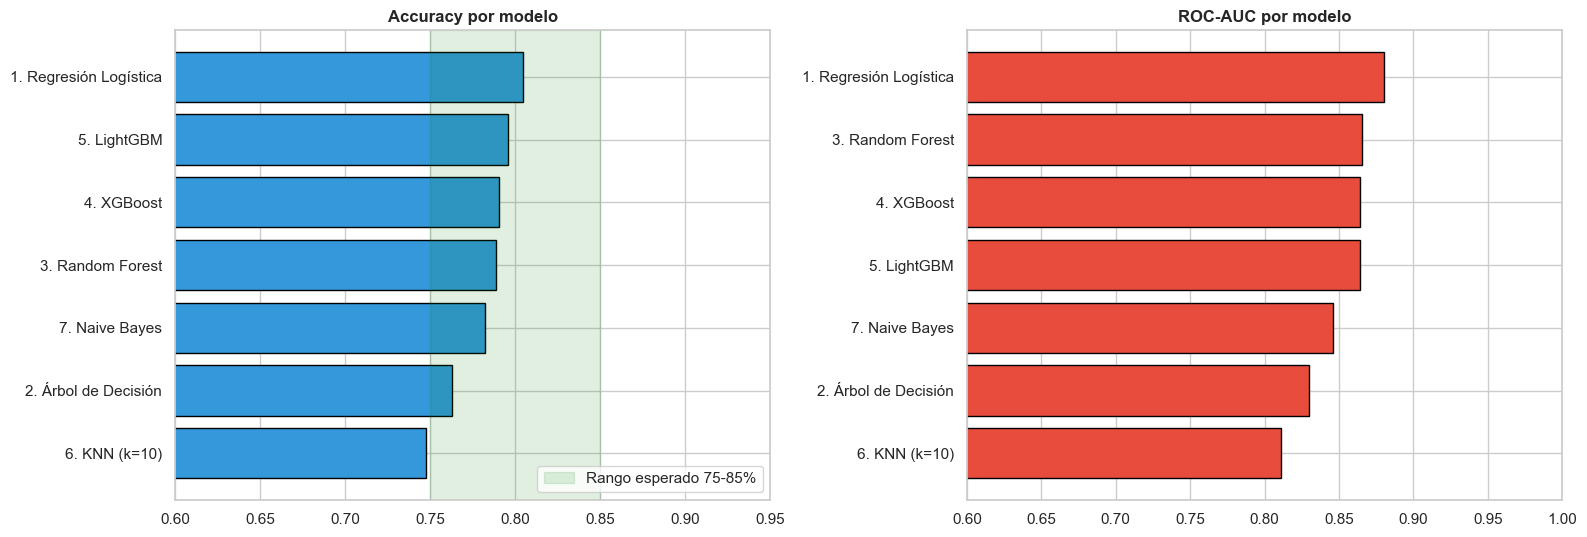

In [6]:
# ============================================================
# Celda 6: Comparación de modelos (selección del mejor)
# ============================================================
print("=" * 70)
print("🤖 COMPARACIÓN DE 7 MODELOS")
print("=" * 70)

ratio = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    '1. Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    '2. Árbol de Decisión': DecisionTreeClassifier(max_depth=8, min_samples_split=20, min_samples_leaf=10,
                                                   class_weight='balanced', random_state=42),
    '3. Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_split=10,
                                               class_weight='balanced', random_state=42, n_jobs=-1),
    '4. XGBoost': XGBClassifier(n_estimators=600, max_depth=5, learning_rate=0.05,
                                scale_pos_weight=ratio, random_state=42, eval_metric='auc', verbosity=0),
    '5. LightGBM': LGBMClassifier(n_estimators=600, max_depth=5, learning_rate=0.05,
                                  scale_pos_weight=ratio, random_state=42, verbose=-1),
    '6. KNN (k=10)': KNeighborsClassifier(n_neighbors=10, weights='distance', n_jobs=-1),
    '7. Naive Bayes': GaussianNB(),
}
ESCALADOS = ['1. Regresión Logística', '6. KNN (k=10)']

resultados = []
for nombre, m in modelos.items():
    inicio = time.time()
    a, b = (X_train_scaled, X_test_scaled) if nombre in ESCALADOS else (X_train, X_test)
    m.fit(a, y_train)
    pred = m.predict(b)
    proba = m.predict_proba(b)[:, 1]
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Tiempo (s)': time.time() - inicio,
    })
    print(f"   ✅ {nombre:26s} Accuracy {resultados[-1]['Accuracy']:.4f} | AUC {resultados[-1]['ROC-AUC']:.4f}")

df_res = pd.DataFrame(resultados).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print("\n📊 TABLA COMPARATIVA (ordenada por ROC-AUC)")
print(df_res.round(4).to_string(index=False))

mejor = df_res.iloc[0]['Modelo']
print(f"\n🏆 MEJOR MODELO: {mejor}  (ROC-AUC {df_res.iloc[0]['ROC-AUC']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
orden = df_res.sort_values('Accuracy')
axes[0].barh(orden['Modelo'], orden['Accuracy'], color='#3498db', edgecolor='black')
axes[0].axvspan(0.75, 0.85, color='green', alpha=0.12, label='Rango esperado 75-85%')
axes[0].set_title('Accuracy por modelo', fontweight='bold')
axes[0].set_xlim(0.6, 0.95)
axes[0].legend(loc='lower right')
orden = df_res.sort_values('ROC-AUC')
axes[1].barh(orden['Modelo'], orden['ROC-AUC'], color='#e74c3c', edgecolor='black')
axes[1].set_title('ROC-AUC por modelo', fontweight='bold')
axes[1].set_xlim(0.6, 1.0)
plt.tight_layout()
guardar('02_comparacion_modelos')
plt.show()

In [7]:
# ============================================================
# Celda 7: Entrenamiento del modelo final (Regresión Logística)
# ============================================================
print("=" * 70)
print("🤖 ENTRENAMIENTO DEL MODELO FINAL: REGRESIÓN LOGÍSTICA")
print("=" * 70)

modelo = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
print(f"\n🔄 Entrenando con {X_train.shape[0]:,} registros...")
modelo.fit(X_train_scaled, y_train)
print("✅ Modelo entrenado exitosamente")

cv = cross_val_score(modelo, X_train_scaled, y_train, cv=5, scoring='roc_auc')
print(f"\n🔁 Validación cruzada (5 particiones) ROC-AUC: {cv.mean():.4f} ± {cv.std():.4f}")

if mejor != '1. Regresión Logística':
    print(f"\n⚠️ OJO: en este KPI el mejor por AUC fue {mejor}. Revisar antes de justificar la Regresión Logística.")
else:
    print("\n✅ La Regresión Logística es el mejor modelo de la comparación para este KPI")

🤖 ENTRENAMIENTO DEL MODELO FINAL: REGRESIÓN LOGÍSTICA

🔄 Entrenando con 9,148 registros...
✅ Modelo entrenado exitosamente

🔁 Validación cruzada (5 particiones) ROC-AUC: 0.8905 ± 0.0106

✅ La Regresión Logística es el mejor modelo de la comparación para este KPI


In [8]:
# ============================================================
# Celda 8: Evaluación de métricas en el set de prueba
# ============================================================
print("=" * 70)
print("📊 EVALUACIÓN DEL MODELO EN SET DE PRUEBA")
print("=" * 70)

y_pred = modelo.predict(X_test_scaled)
y_pred_proba = modelo.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)
avg_precision = average_precision_score(y_test, y_pred_proba)

print(f"\n🎯 MÉTRICAS PRINCIPALES:")
print(f"   • Accuracy:       {accuracy:.4f} ({accuracy:.2%})")
print(f"   • Precision:      {precision:.4f}")
print(f"   • Recall:         {recall:.4f}")
print(f"   • F1-Score:       {f1:.4f}")
print(f"   • ROC-AUC:        {auc:.4f}")
print(f"   • Avg Precision:  {avg_precision:.4f}")

print(f"\n📋 REPORTE DE CLASIFICACIÓN COMPLETO:")
print("-" * 70)
print(classification_report(y_test, y_pred, target_names=['No recontacta (0)', 'Recontacta (1)']))

print(f"💡 INTERPRETACIÓN:")
print(f"   • ROC-AUC = {auc:.3f} indica un poder discriminatorio "
      f"{'excelente' if auc > 0.85 else 'bueno' if auc > 0.75 else 'moderado'}")
print(f"   • Accuracy {'dentro' if 0.75 <= accuracy <= 0.85 else 'fuera'} del rango esperado (75%-85%)")
print(f"   • {'No hay indicio de data leakage (accuracy < 90%)' if accuracy < 0.90 else 'ALERTA: accuracy > 90%, revisar posible data leakage'}")
print(f"   • CV-AUC {cv.mean():.3f} vs AUC de prueba {auc:.3f}: diferencia {abs(cv.mean() - auc):.3f} "
      f"({'sin sobreajuste evidente' if abs(cv.mean() - auc) < 0.03 else 'revisar sobreajuste'})")

📊 EVALUACIÓN DEL MODELO EN SET DE PRUEBA

🎯 MÉTRICAS PRINCIPALES:
   • Accuracy:       0.8042 (80.42%)
   • Precision:      0.7413
   • Recall:         0.8116
   • F1-Score:       0.7749
   • ROC-AUC:        0.8803
   • Avg Precision:  0.8460

📋 REPORTE DE CLASIFICACIÓN COMPLETO:
----------------------------------------------------------------------
                   precision    recall  f1-score   support

No recontacta (0)       0.86      0.80      0.83      1338
   Recontacta (1)       0.74      0.81      0.77       950

         accuracy                           0.80      2288
        macro avg       0.80      0.81      0.80      2288
     weighted avg       0.81      0.80      0.81      2288

💡 INTERPRETACIÓN:
   • ROC-AUC = 0.880 indica un poder discriminatorio excelente
   • Accuracy dentro del rango esperado (75%-85%)
   • No hay indicio de data leakage (accuracy < 90%)
   • CV-AUC 0.891 vs AUC de prueba 0.880: diferencia 0.010 (sin sobreajuste evidente)


In [9]:
# ============================================================
# Celda 8b: Verificación anti-fuga de datos (data leakage)
# ============================================================
print("=" * 70)
print("🛡️ VERIFICACIÓN ANTI-FUGA DE DATOS")
print("=" * 70)

# 1) Ninguna variable del modelo contiene el resultado
sospechosas = [c for c in X.columns if 'recontacto' in c.lower()]
print(f"\n1) Variables con 'recontacto' en el nombre dentro del modelo: {sospechosas if sospechosas else 'ninguna ✅'}")

# 2) Ninguna variable por sí sola separa casi perfectamente el target
aucs = {}
for c in X.columns:
    if X[c].nunique() > 1:
        a = roc_auc_score(y, X[c])
        aucs[c] = max(a, 1 - a)
aucs = pd.Series(aucs).sort_values(ascending=False)
print(f"\n2) AUC individual más alto de una sola variable: {aucs.index[0]} = {aucs.iloc[0]:.3f}")
print(f"   {'✅ ninguna variable por sí sola explica el target (umbral de alerta: 0.95)' if aucs.iloc[0] < 0.95 else '⚠️ revisar: una variable casi separa el target'}")
print(aucs.head(5).round(3).to_string())

# 3) Rendimiento realista y estable
print(f"\n3) Accuracy {accuracy:.2%} (alerta si > 90%): {'✅' if accuracy < 0.90 else '⚠️'}")
print(f"4) CV-AUC {cv.mean():.3f} vs AUC prueba {auc:.3f} (diferencia {abs(cv.mean() - auc):.3f}): "
      f"{'✅ estable' if abs(cv.mean() - auc) < 0.03 else '⚠️ revisar'}")

print("""
5) Diseño de las variables (variables congeladas en el tiempo):
   • duracion_seg, espera_seg y transferencias describen el contacto original, no el recontacto.
   • casos_previos_30d se calcula solo con contactos ANTERIORES del mismo usuario.
   • Se excluyen del modelo: id_interaccion, fecha_contacto y el propio target.
""")

🛡️ VERIFICACIÓN ANTI-FUGA DE DATOS

1) Variables con 'recontacto' en el nombre dentro del modelo: ninguna ✅

2) AUC individual más alto de una sola variable: transferencias = 0.741
   ✅ ninguna variable por sí sola explica el target (umbral de alerta: 0.95)
transferencias            0.741
espera_seg                0.721
es_multi_transferencia    0.645
es_espera_alta            0.644
casos_previos_30d         0.638

3) Accuracy 80.42% (alerta si > 90%): ✅
4) CV-AUC 0.891 vs AUC prueba 0.880 (diferencia 0.010): ✅ estable

5) Diseño de las variables (variables congeladas en el tiempo):
   • duracion_seg, espera_seg y transferencias describen el contacto original, no el recontacto.
   • casos_previos_30d se calcula solo con contactos ANTERIORES del mismo usuario.
   • Se excluyen del modelo: id_interaccion, fecha_contacto y el propio target.



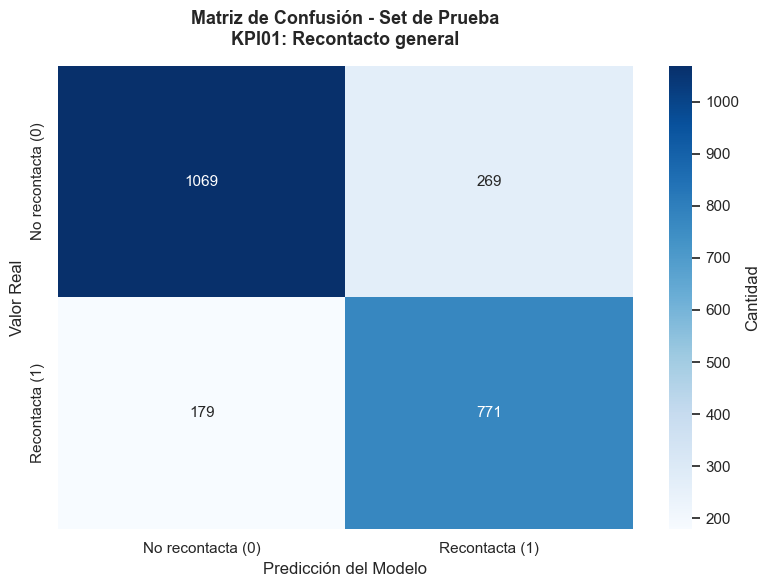


📊 DESGLOSE DE LA MATRIZ:
   • Verdaderos Positivos (VP):   771 → Recontactos detectados correctamente
   • Verdaderos Negativos (VN):  1069 → Casos resueltos identificados correctamente
   • Falsos Positivos (FP):       269 → Alarmas falsas (se predijo recontacto y no ocurrió)
   • Falsos Negativos (FN):       179 → Recontactos que el modelo no detectó

💼 LECTURA OPERATIVA:
   • De 950 recontactos reales, el modelo anticipó 771 (81.2%)
   • De 1,040 casos marcados como riesgo, 771 sí recontactaron (74.1%)
   • Seguimientos que serían innecesarios: 269


In [10]:
# ============================================================
# Celda 9: Matriz de confusión
# ============================================================
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No recontacta (0)', 'Recontacta (1)'],
            yticklabels=['No recontacta (0)', 'Recontacta (1)'],
            cbar_kws={'label': 'Cantidad'})
plt.title(f'Matriz de Confusión - Set de Prueba\n{KPI_ID}: {KPI_NOMBRE}', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Valor Real')
plt.xlabel('Predicción del Modelo')
plt.tight_layout()
guardar('03_matriz_confusion')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"\n📊 DESGLOSE DE LA MATRIZ:")
print(f"   • Verdaderos Positivos (VP): {tp:5d} → Recontactos detectados correctamente")
print(f"   • Verdaderos Negativos (VN): {tn:5d} → Casos resueltos identificados correctamente")
print(f"   • Falsos Positivos (FP):     {fp:5d} → Alarmas falsas (se predijo recontacto y no ocurrió)")
print(f"   • Falsos Negativos (FN):     {fn:5d} → Recontactos que el modelo no detectó")

print(f"\n💼 LECTURA OPERATIVA:")
print(f"   • De {tp + fn:,} recontactos reales, el modelo anticipó {tp:,} ({tp / (tp + fn):.1%})")
print(f"   • De {tp + fp:,} casos marcados como riesgo, {tp:,} sí recontactaron ({tp / (tp + fp):.1%})")
print(f"   • Seguimientos que serían innecesarios: {fp:,}")

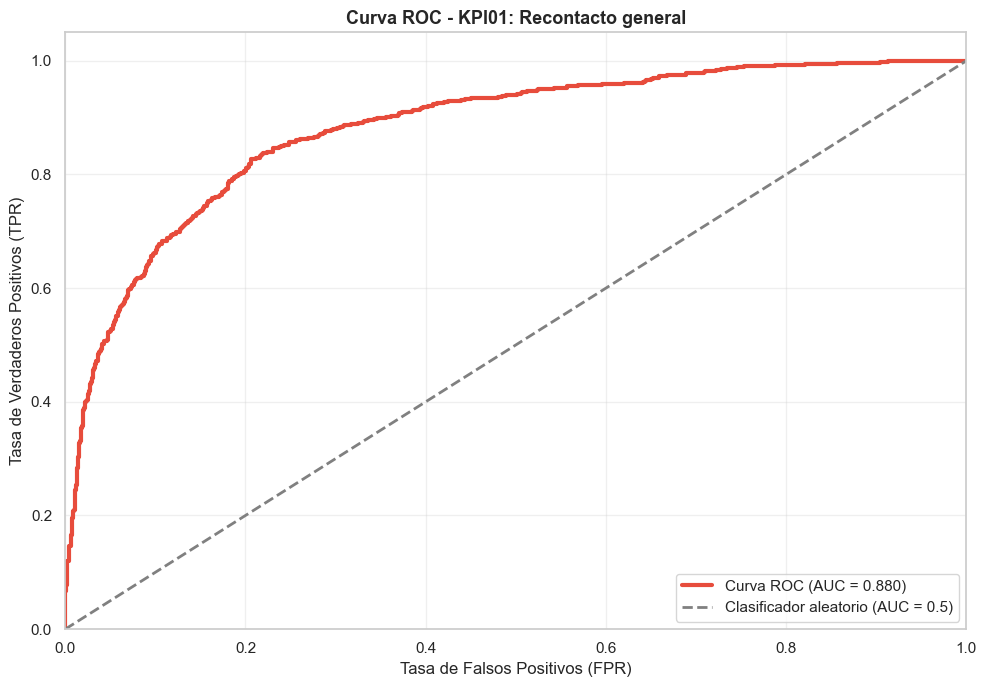


🎯 UMBRAL ÓPTIMO (máximo de TPR - FPR):
   • Umbral: 0.478
   • TPR en ese punto: 0.826
   • FPR en ese punto: 0.206


In [11]:
# ============================================================
# Celda 10: Curva ROC
# ============================================================
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(10, 7))
plt.plot(fpr, tpr, color='#e74c3c', lw=3, label=f'Curva ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Clasificador aleatorio (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title(f'Curva ROC - {KPI_ID}: {KPI_NOMBRE}', fontsize=13, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
guardar('04_curva_roc')
plt.show()

idx_optimo = np.argmax(tpr - fpr)
umbral_optimo = thresholds[idx_optimo]
print(f"\n🎯 UMBRAL ÓPTIMO (máximo de TPR - FPR):")
print(f"   • Umbral: {umbral_optimo:.3f}")
print(f"   • TPR en ese punto: {tpr[idx_optimo]:.3f}")
print(f"   • FPR en ese punto: {fpr[idx_optimo]:.3f}")

🔍 VARIABLES MÁS ASOCIADAS AL RECONTACTO (COEFICIENTES)

📊 TOP 15 VARIABLES (odds ratio por cada desviación estándar):
----------------------------------------------------------------------
    1. transferencias               | coef +1.5146 | OR 4.548 | ↑ sube la prob.
    2. casos_previos_30d            | coef +0.9228 | OR 2.516 | ↑ sube la prob.
    3. espera_seg                   | coef +0.9167 | OR 2.501 | ↑ sube la prob.
    4. cola_reclamos                | coef -0.4004 | OR 0.670 | ↓ baja la prob.
    5. es_duracion_corta            | coef +0.3706 | OR 1.449 | ↑ sube la prob.
    6. duracion_seg                 | coef +0.3558 | OR 1.427 | ↑ sube la prob.
    7. usuario_adulto_mayor         | coef +0.3336 | OR 1.396 | ↑ sube la prob.
    8. usuario_empresa              | coef -0.2846 | OR 0.752 | ↓ baja la prob.
    9. cola_soporte                 | coef -0.2392 | OR 0.787 | ↓ baja la prob.
   10. cola_informacion             | coef +0.2308 | OR 1.260 | ↑ sube la prob.
   11. cana

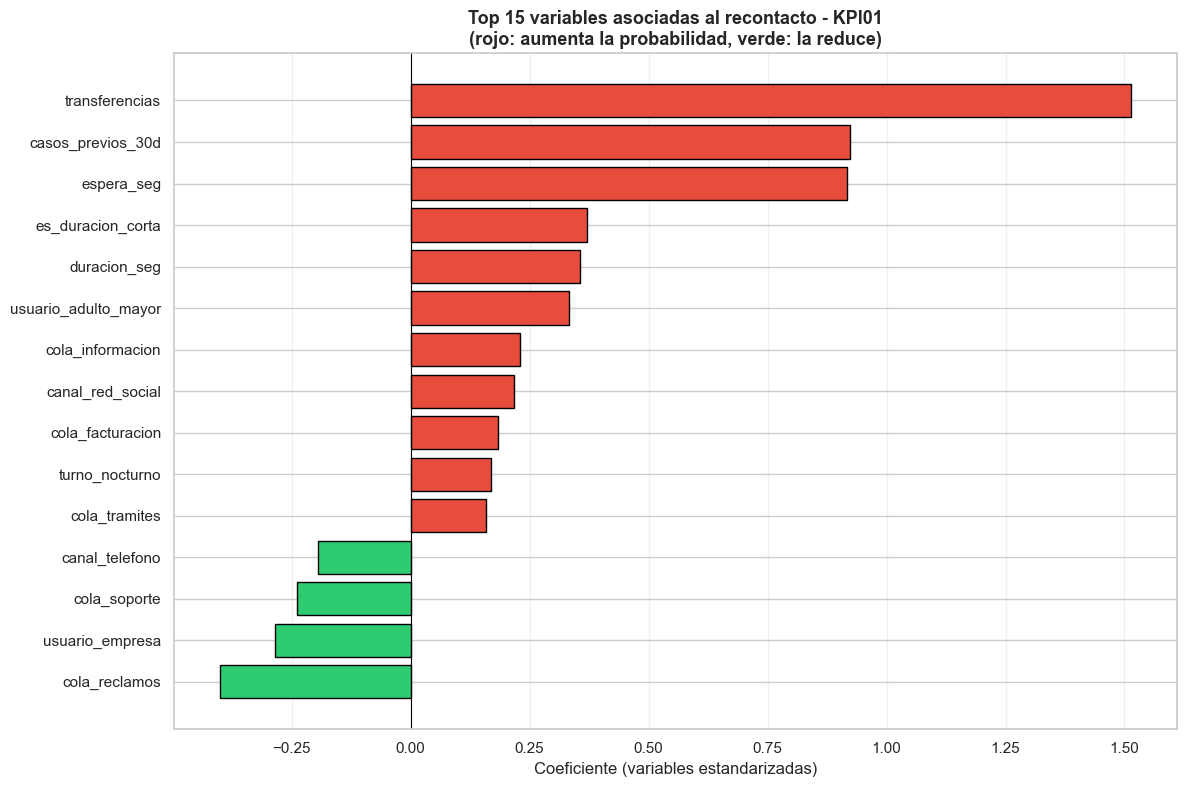


⚠️ Los coeficientes indican ASOCIACIÓN, no causalidad.


In [12]:
# ============================================================
# Celda 11: Variables más asociadas al recontacto
# ============================================================
print("=" * 70)
print("🔍 VARIABLES MÁS ASOCIADAS AL RECONTACTO (COEFICIENTES)")
print("=" * 70)

df_coef = pd.DataFrame({'Variable': X.columns, 'Coeficiente': modelo.coef_[0]})
df_coef['Odds ratio'] = np.exp(df_coef['Coeficiente'])
df_coef['Abs'] = df_coef['Coeficiente'].abs()
df_coef = df_coef.sort_values('Abs', ascending=False).reset_index(drop=True)
top15 = df_coef.head(15)

print(f"\n📊 TOP 15 VARIABLES (odds ratio por cada desviación estándar):")
print("-" * 70)
for i, r in top15.iterrows():
    signo = '↑ sube' if r['Coeficiente'] > 0 else '↓ baja'
    print(f"   {i + 1:2d}. {r['Variable']:28s} | coef {r['Coeficiente']:+.4f} | OR {r['Odds ratio']:.3f} | {signo} la prob.")

plot_data = top15.sort_values('Coeficiente')
colores = ['#e74c3c' if c > 0 else '#2ecc71' for c in plot_data['Coeficiente']]
plt.figure(figsize=(12, 8))
plt.barh(plot_data['Variable'], plot_data['Coeficiente'], color=colores, edgecolor='black')
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Coeficiente (variables estandarizadas)')
plt.title(f'Top 15 variables asociadas al recontacto - {KPI_ID}\n(rojo: aumenta la probabilidad, verde: la reduce)',
          fontsize=13, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
guardar('05_coeficientes')
plt.show()

print("\n⚠️ Los coeficientes indican ASOCIACIÓN, no causalidad.")

💼 RECONTACTO POR SEGMENTO


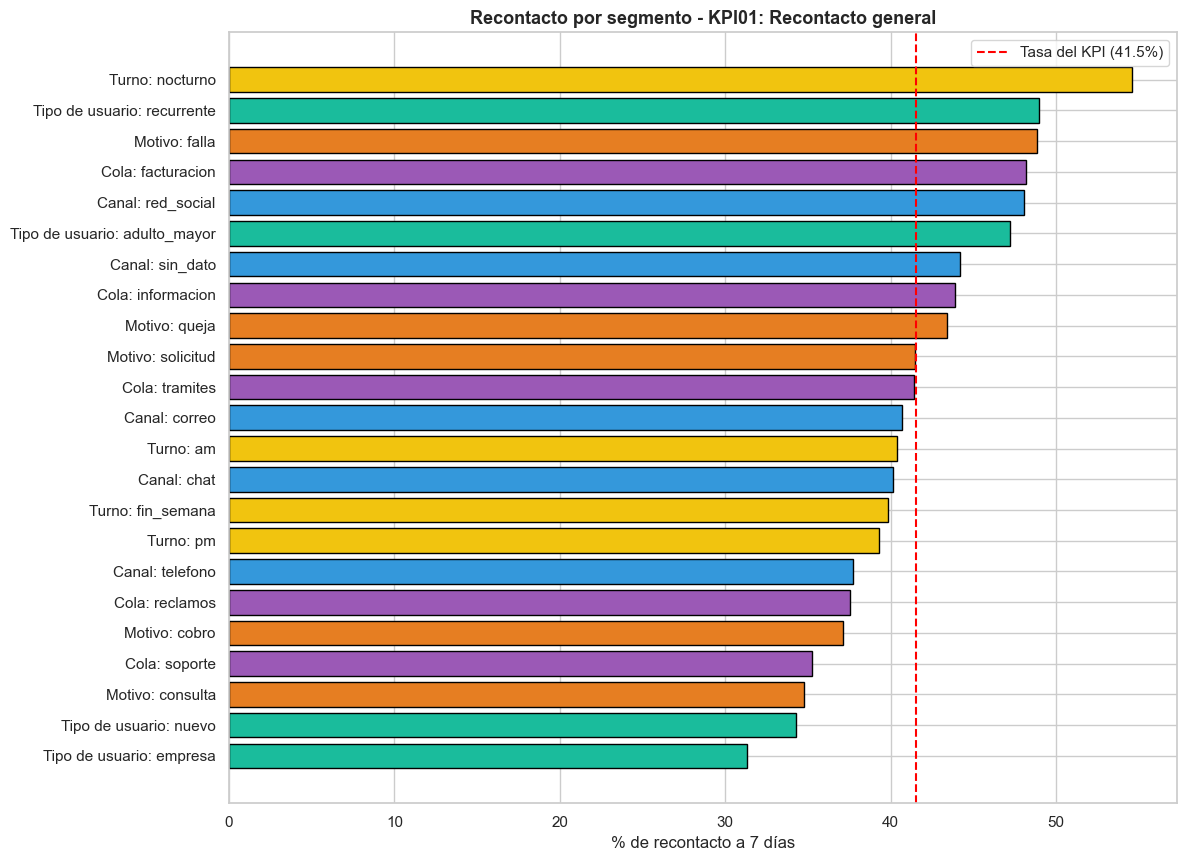


🔺 SEGMENTOS CON MAYOR RECONTACTO:
                   Etiqueta  Casos  Tasa %
            Turno: nocturno   1323    54.6
Tipo de usuario: recurrente   3933    48.9
              Motivo: falla   2528    48.9
          Cola: facturacion   2110    48.2
          Canal: red_social   2552    48.0

🔻 SEGMENTOS CON MENOR RECONTACTO:
                Etiqueta  Casos  Tasa %
Tipo de usuario: empresa   1718    31.3
  Tipo de usuario: nuevo   3439    34.3
        Motivo: consulta   1895    34.8
           Cola: soporte   2240    35.2
           Motivo: cobro   2319    37.1


In [13]:
# ============================================================
# Celda 12: Tasa de recontacto por segmento (reglas de negocio)
# ============================================================
print("=" * 70)
print("💼 RECONTACTO POR SEGMENTO")
print("=" * 70)

grupos = {'Canal': 'canal_', 'Motivo': 'motivo_', 'Cola': 'cola_',
          'Tipo de usuario': 'usuario_', 'Turno': 'turno_'}
tasa_kpi = df['es_recontacto'].mean() * 100

filas = []
for g, pref in grupos.items():
    for col in [c for c in df.columns if c.startswith(pref)]:
        m = df[col] == 1
        if m.sum() >= 30:
            filas.append({'Grupo': g, 'Segmento': col.replace(pref, ''),
                          'Casos': int(m.sum()),
                          'Tasa %': df.loc[m, 'es_recontacto'].mean() * 100})
seg = pd.DataFrame(filas).sort_values('Tasa %', ascending=True).reset_index(drop=True)
seg['Etiqueta'] = seg['Grupo'] + ': ' + seg['Segmento']

paleta = {'Canal': '#3498db', 'Motivo': '#e67e22', 'Cola': '#9b59b6',
          'Tipo de usuario': '#1abc9c', 'Turno': '#f1c40f'}
plt.figure(figsize=(12, max(6, len(seg) * 0.38)))
plt.barh(seg['Etiqueta'], seg['Tasa %'], color=[paleta[g] for g in seg['Grupo']], edgecolor='black')
plt.axvline(tasa_kpi, color='red', ls='--', label=f'Tasa del KPI ({tasa_kpi:.1f}%)')
plt.xlabel('% de recontacto a 7 días')
plt.title(f'Recontacto por segmento - {KPI_ID}: {KPI_NOMBRE}', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
guardar('06_segmentos')
plt.show()

print(f"\n🔺 SEGMENTOS CON MAYOR RECONTACTO:")
print(seg.tail(5).iloc[::-1][['Etiqueta', 'Casos', 'Tasa %']].round(1).to_string(index=False))
print(f"\n🔻 SEGMENTOS CON MENOR RECONTACTO:")
print(seg.head(5)[['Etiqueta', 'Casos', 'Tasa %']].round(1).to_string(index=False))

In [14]:
# ============================================================
# Celda 13: Cifras para el reporte ejecutivo (calculadas)
# El ANÁLISIS se redacta a mano en la celda de texto que sigue.
# ============================================================
ACCIONES = {
    'transferencias': 'Reducir transferencias: mejorar el ruteo para resolver en el primer contacto',
    'espera_seg': 'Reducir el tiempo de espera: ajustar dotación y priorizar colas críticas',
    'casos_previos_30d': 'Seguimiento proactivo a usuarios con casos previos recientes',
    'es_duracion_corta': 'Revisar atenciones muy cortas: pueden cerrarse sin resolver',
    'duracion_seg': 'Revisar la duración de atención frente al tipo de caso',
    'usuario_adulto_mayor': 'Atención asistida y confirmación de resolución a adultos mayores',
    'turno_nocturno': 'Reforzar capacidad de resolución en turno nocturno',
    'canal_red_social': 'Mejorar la resolución en redes sociales o derivar a un canal con trazabilidad',
    'cola_informacion': 'Revisar la calidad de las respuestas en la cola de Información',
    'cola_facturacion': 'Revisar casos de Facturación para resolver en el primer contacto',
    'cola_tramites': 'Simplificar el seguimiento de Trámites',
}
REDUCCION_SUPUESTA = 0.15   # SUPUESTO de trabajo, no es un dato: % de recontactos detectados que se logra evitar

tasa_kpi = df['es_recontacto'].mean() * 100
n_casos = len(df)
n_rec = int(df['es_recontacto'].sum())
dur_media = df['duracion_seg'].mean()
recall_ = tp / (tp + fn)

horas_rec = n_rec * dur_media / 3600
evitables = n_rec * recall_ * REDUCCION_SUPUESTA
horas_ahorradas = evitables * dur_media / 3600
tasa_proy = tasa_kpi - tasa_kpi * recall_ * REDUCCION_SUPUESTA
brecha_actual = tasa_kpi - META_RECONTACTO
brecha_proy = tasa_proy - META_RECONTACTO

print("=" * 70)
print(f"📊 CIFRAS DEL REPORTE - {KPI_ID}: {KPI_NOMBRE}")
print("=" * 70)
print(f"""
🎯 OBJETIVO: {OBJETIVO}
🔖 TARGET : {TARGET_DEF}

📊 DATOS
   • Casos del KPI: {n_casos:,}  |  Recontactos: {n_rec:,}  |  Tasa actual: {tasa_kpi:.2f}%
   • Meta (proxy): ≤ {META_RECONTACTO:.0f}%  |  Brecha actual: {brecha_actual:.1f} puntos
   • Entrenamiento / prueba: {len(X_train):,} / {len(X_test):,}  |  Variables: {X.shape[1]}

🤖 MODELO: Regresión Logística (mejor de 7 por ROC-AUC: {mejor})
   • Accuracy {accuracy:.2%} | Precision {precision:.2%} | Recall {recall:.2%} | F1 {f1:.4f} | ROC-AUC {auc:.4f}
   • CV-AUC (5 particiones): {cv.mean():.4f} ± {cv.std():.4f}
   • Recontactos detectados: {tp:,} de {tp + fn:,} ({recall_:.1%}) | Alarmas falsas: {fp:,}

⏱️ CARGA OPERATIVA (estimación con la duración media del contacto = {dur_media:.0f} s)
   • Horas-agente que consumen los recontactos del periodo: ≈ {horas_rec:,.0f} h

💰 ESCENARIO ILUSTRATIVO (supuesto declarado: se evita el {REDUCCION_SUPUESTA:.0%} de los recontactos detectados)
   • Recontactos evitables: ≈ {evitables:,.0f}  |  Horas-agente liberadas: ≈ {horas_ahorradas:,.0f} h
   • La tasa bajaría de {tasa_kpi:.1f}% a ≈ {tasa_proy:.1f}%  |  Brecha restante frente a la meta: {brecha_proy:.1f} puntos
   • El {REDUCCION_SUPUESTA:.0%} es un supuesto de trabajo, no un resultado del modelo.
""")

pos = df_coef[df_coef['Coeficiente'] > 0]
prioridades = ['URGENTE', 'ALTO', 'ALTO', 'MEDIO', 'MEDIO', 'MEDIO']
print("🚀 ACCIONES PRIORIZADAS (hipótesis a validar con prueba A/B; prioridad según la asociación)")
print("-" * 70)
n = 0
for _, r in pos.iterrows():
    if r['Variable'] in ACCIONES and n < len(prioridades):
        print(f"   {prioridades[n]:8s} {ACCIONES[r['Variable']]}")
        print(f"            (variable: {r['Variable']} | odds ratio {r['Odds ratio']:.2f} por desv. estándar)")
        n += 1

print("\n🔻 VARIABLES QUE MÁS REDUCEN LA PROBABILIDAD DE RECONTACTO:")
for _, r in df_coef[df_coef['Coeficiente'] < 0].head(3).iterrows():
    print(f"   ↓ {r['Variable']:26s} (odds ratio {r['Odds ratio']:.2f})")

📊 CIFRAS DEL REPORTE - KPI01: Recontacto general

🎯 OBJETIVO: Reducir la tasa de recontacto a 7 días en el Servicio Ciudadano 1800
🔖 TARGET : es_recontacto: 1 = el usuario vuelve a contactar por el mismo motivo en 7 días; 0 = no vuelve; los casos con resultado vacío (no consolidado) se excluyen del modelo

📊 DATOS
   • Casos del KPI: 11,436  |  Recontactos: 4,749  |  Tasa actual: 41.53%
   • Meta (proxy): ≤ 22%  |  Brecha actual: 19.5 puntos
   • Entrenamiento / prueba: 9,148 / 2,288  |  Variables: 31

🤖 MODELO: Regresión Logística (mejor de 7 por ROC-AUC: 1. Regresión Logística)
   • Accuracy 80.42% | Precision 74.13% | Recall 81.16% | F1 0.7749 | ROC-AUC 0.8803
   • CV-AUC (5 particiones): 0.8905 ± 0.0106
   • Recontactos detectados: 771 de 950 (81.2%) | Alarmas falsas: 269

⏱️ CARGA OPERATIVA (estimación con la duración media del contacto = 981 s)
   • Horas-agente que consumen los recontactos del periodo: ≈ 1,294 h

💰 ESCENARIO ILUSTRATIVO (supuesto declarado: se evita el 15% de lo

# Fase 15: Reporte ejecutivo (redactado por el analista)

**Objetivo.** Reducir la tasa de recontacto a 7 días del Servicio Ciudadano 1800, hoy en 41.5%, frente a una meta de referencia de ≤ 22%. La meta es un proxy: surge del 78% de resolución en primer contacto que el caso entrega como referencia, y debe validarse.

**Hallazgo central.** El modelo (Regresión Logística, ROC-AUC 0.880, accuracy 80.4%) anticipa 8 de cada 10 recontactos (recall 81.2%). La probabilidad de recontacto se asocia sobre todo con tres factores operativos: el número de transferencias, los casos previos del usuario en los últimos 30 días y el tiempo de espera. Los usuarios empresa y la cola de Reclamos muestran menor probabilidad.

**Lectura de negocio.** Las transferencias son la señal más fuerte; resolver en el primer contacto, con mejor ruteo, es la acción prioritaria. Después va el seguimiento proactivo a usuarios con casos recientes, y luego la reducción de la espera. Por segmentos, el turno nocturno (54.6%), los usuarios recurrentes y los casos por falla (48.9%) superan el promedio.

**Alcance realista.** Aun si se evitara el 15% de los recontactos detectados (supuesto), la tasa bajaría a ≈ 36.5%, todavía lejos de la meta. El modelo ayuda a priorizar, pero no basta por sí solo para alcanzarla.

# Fase 16: Próximos pasos y limitaciones

**Próximos pasos.**
1. Validar con la dirección la meta de recontacto y el criterio de "mismo motivo".
2. Probar las intervenciones con una prueba A/B en las colas con mayor recontacto.
3. Monitorear mensualmente la tasa de recontacto y las métricas del modelo.
4. Reentrenar con datos reales cada trimestre.

**Limitaciones.**
- Los datos son sintéticos. Las relaciones entre variables son supuestos documentados del generador, y su intensidad se calibró para que el modelo quedara en el rango esperado de 75–85%.
- La Regresión Logística gana en parte porque el generador usa una fórmula logística.
- Los coeficientes indican asociación, no causalidad.
- No se dispone de costos por contacto, por lo que el impacto se expresa en casos y horas-agente, con un supuesto del 15% declarado.
- Los 5 KPIs comparten el mismo evento (recontacto) y difieren en la población analizada.
- Parte del recontacto no es evitable (usuarios con consultas nuevas o complejas), por lo que conviene aceptar un piso mínimo.